In [ ]:
import sys
import torch
sys.path.insert(0,"../src")

from cnn_project.train import train_model
from cnn_project.model import EuroSATModel, model_tensor_size_mib
from cnn_project.evaluate import evaluate_model
from cnn_project.data import create_data_loaders
from pathlib import Path


First, select the training device. Each experiment creates its own model and data loaders.


In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("The model is using CUDA")
else:
    device = torch.device("cpu")
    print("The model is using CPU")



The model is using CUDA


First use the functions to train and then to evaluate the model

This takes around 3-4 minutes to complete

In [ ]:
import json

seed = 42
run_dir = Path("../Checkpoints/base_models")
model_dirs = {i: run_dir / f"model{i}" for i in (1, 2, 3)}
for model_dir in model_dirs.values():
    model_dir.mkdir(parents=True, exist_ok=True)
best_checkpoint_path_model1 = model_dirs[1] / "best.pt"
best_checkpoint_path_model2 = model_dirs[2] / "best.pt"
best_checkpoint_path_model3 = model_dirs[3] / "best.pt"
print(f"Saving latest comparison to {run_dir} (existing files will be replaced)")

torch.manual_seed(seed)
model1 = EuroSATModel(channels=(16, 32, 64, 128)).to(device)
model1.compile(
    backend="inductor",
    options={"layout_optimization": False},
)
train_loader, val_loader, test_loader = create_data_loaders(
    batch_size=64, num_workers=10, generator=torch.Generator().manual_seed(seed)
)

history_model1 = train_model(
    model=model1, train_loader=train_loader, val_loader=val_loader, lr= 0.00633, gamma= 0.696,
    device=device, epochs=100, checkpoint_path=best_checkpoint_path_model1, step_size=4
)
model1.load_state_dict(torch.load(best_checkpoint_path_model1, map_location=device, weights_only=True))
(model_dirs[1] / "config.json").write_text(json.dumps({
    "channels": [16, 32, 64, 128], "seed": seed, "epochs": 100,
    "learning_rate": 0.00633, "gamma": 0.696, "step_size": 4,
}, indent=2) + "\n")
best_row = max(range(len(history_model1["epoch"])), key=lambda i: history_model1["val_accuracy"][i])
print(f"Using epoch {history_model1['epoch'][best_row]} with validation accuracy "
      f"{history_model1['val_accuracy'][best_row]:.2%}")
train_correct_model1, train_total_model1 = evaluate_model(model=model1, dataset_loader=train_loader, device=device)
val_correct_model1, val_total_model1 = evaluate_model(model=model1, dataset_loader=val_loader, device=device)
print("Model 1 with (16, 32, 64, 128)")
print(f"Train Accuracy: {100 * train_correct_model1 / train_total_model1:.4f}%, "
      f"Val Accuracy: {100 * val_correct_model1 / val_total_model1:.4f}%")



torch.manual_seed(seed)
model2 = EuroSATModel(channels=(32, 64, 128, 256)).to(device)
model2.compile(
    backend="inductor",
    options={"layout_optimization": False},
)
train_loader, val_loader, test_loader = create_data_loaders(
    batch_size=64, num_workers=10, generator=torch.Generator().manual_seed(seed)
)
history_model2 = train_model(
    model=model2, train_loader=train_loader, val_loader=val_loader, lr= 0.00633, gamma= 0.696,
    device=device, epochs=100, checkpoint_path=best_checkpoint_path_model2, step_size=4
)
model2.load_state_dict(torch.load(best_checkpoint_path_model2, map_location=device, weights_only=True))
(model_dirs[2] / "config.json").write_text(json.dumps({
    "channels": [32, 64, 128, 256], "seed": seed, "epochs": 100,
    "learning_rate": 0.00633, "gamma": 0.696, "step_size": 4,
}, indent=2) + "\n")
best_row = max(range(len(history_model2["epoch"])), key=lambda i: history_model2["val_accuracy"][i])
print(f"Using epoch {history_model2['epoch'][best_row]} with validation accuracy "
      f"{history_model2['val_accuracy'][best_row]:.2%}")
train_correct_model2, train_total_model2 = evaluate_model(model=model2, dataset_loader=train_loader, device=device)
val_correct_model2, val_total_model2 = evaluate_model(model=model2, dataset_loader=val_loader, device=device)
print("Model 2 with (32, 64, 128, 256)")
print(f"Train Accuracy: {100 * train_correct_model2 / train_total_model2:.4f}%, "
      f"Val Accuracy: {100 * val_correct_model2 / val_total_model2:.4f}%")



torch.manual_seed(seed)
model3 = EuroSATModel(channels=(64, 128, 256, 512)).to(device)
model3.compile(
    backend="inductor",
    options={"layout_optimization": False},
)
train_loader, val_loader, test_loader = create_data_loaders(
    batch_size=64, num_workers=10, generator=torch.Generator().manual_seed(seed)
)
history_model3 = train_model(
    model=model3, train_loader=train_loader, val_loader=val_loader, lr= 0.00633, gamma= 0.696,
    device=device, epochs=100, checkpoint_path=best_checkpoint_path_model3, step_size=4
)
model3.load_state_dict(torch.load(best_checkpoint_path_model3, map_location=device, weights_only=True))
(model_dirs[3] / "config.json").write_text(json.dumps({
    "channels": [64, 128, 256, 512], "seed": seed, "epochs": 100,
    "learning_rate": 0.00633, "gamma": 0.696, "step_size": 4,
}, indent=2) + "\n")
best_row = max(range(len(history_model3["epoch"])), key=lambda i: history_model3["val_accuracy"][i])
print(f"Using epoch {history_model3['epoch'][best_row]} with validation accuracy "
      f"{history_model3['val_accuracy'][best_row]:.2%}")
train_correct_model3, train_total_model3 = evaluate_model(model=model3, dataset_loader=train_loader, device=device)
val_correct_model3, val_total_model3 = evaluate_model(model=model3, dataset_loader=val_loader, device=device)
print("Model 3 with (64,128,256,512)")
print(f"Train Accuracy: {100 * train_correct_model3 / train_total_model3:.4f}%, "
      f"Val Accuracy: {100 * val_correct_model3 / val_total_model3:.4f}%")

Saving this comparison to ../Checkpoints/width_comparison_495773002b8d44c78cce4383ad77f925
Training model...
Epoch 1, Loss: 1.1585, Accuracy: 0.5910, LR: 0.0063300000, Val loss: 1.7839, Val accuracy: 0.5556
Epoch 2, Loss: 0.7806, Accuracy: 0.7179, LR: 0.0063300000, Val loss: 0.6853, Val accuracy: 0.7474
Epoch 3, Loss: 0.6695, Accuracy: 0.7592, LR: 0.0063300000, Val loss: 0.5666, Val accuracy: 0.7985
Epoch 4, Loss: 0.5938, Accuracy: 0.7925, LR: 0.0063300000, Val loss: 0.6629, Val accuracy: 0.7685
Epoch 5, Loss: 0.5027, Accuracy: 0.8226, LR: 0.0044056800, Val loss: 0.4539, Val accuracy: 0.8367
Epoch 6, Loss: 0.4521, Accuracy: 0.8424, LR: 0.0044056800, Val loss: 0.6031, Val accuracy: 0.8037
Epoch 7, Loss: 0.4266, Accuracy: 0.8525, LR: 0.0044056800, Val loss: 0.3489, Val accuracy: 0.8841
Epoch 8, Loss: 0.3966, Accuracy: 0.8613, LR: 0.0044056800, Val loss: 0.5653, Val accuracy: 0.7937
Epoch 9, Loss: 0.3464, Accuracy: 0.8817, LR: 0.0030663533, Val loss: 0.2776, Val accuracy: 0.9026
Epoch 10,

Save the per-epoch metrics as CSV and plot training and validation curves. The dashed line marks the second training stage.

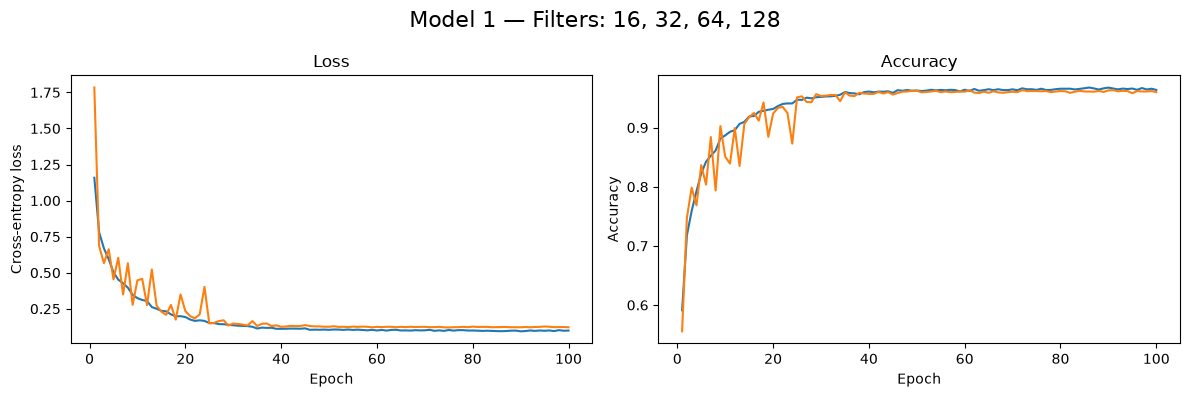

Saved history to ../Checkpoints/width_comparison_495773002b8d44c78cce4383ad77f925/training_history_model1.csv


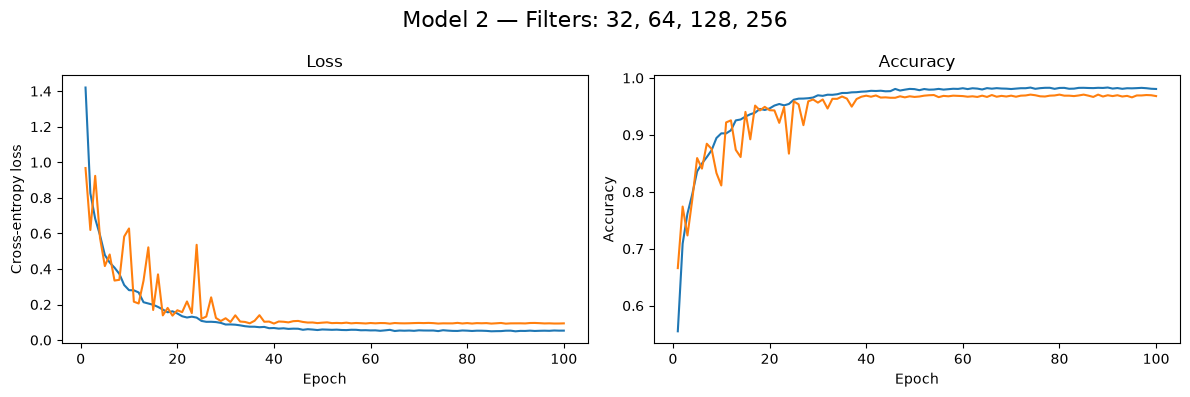

Saved history to ../Checkpoints/width_comparison_495773002b8d44c78cce4383ad77f925/training_history_model2.csv


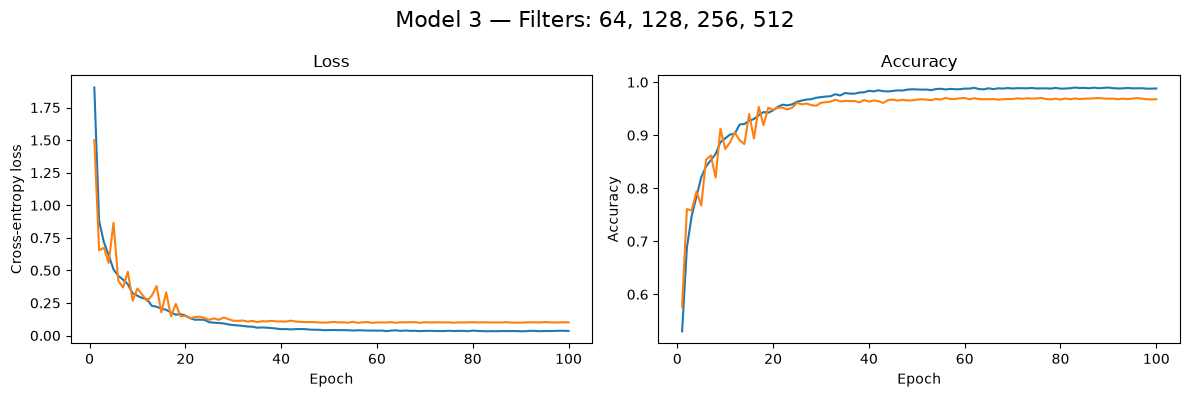

Saved history to ../Checkpoints/width_comparison_495773002b8d44c78cce4383ad77f925/training_history_model3.csv


In [6]:
import csv
import matplotlib.pyplot as plt

history_path1 = model_dirs[1] / "history.csv"
history_path1.parent.mkdir(parents=True, exist_ok=True)
with history_path1.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(history_model1.keys())
    writer.writerows(zip(*history_model1.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_model1["epoch"], history_model1["train_loss"], label="Training")
axes[0].plot(history_model1["epoch"], history_model1["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history_model1["epoch"], history_model1["train_accuracy"], label="Training")
axes[1].plot(history_model1["epoch"], history_model1["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
fig.suptitle("Model 1 — Filters: 16, 32, 64, 128", fontsize=16)
fig.tight_layout()
fig.savefig(model_dirs[1] / "curves.png", dpi=150)
plt.show()
print(f"Saved history to {history_path1}")



history_path2 = model_dirs[2] / "history.csv"
history_path2.parent.mkdir(parents=True, exist_ok=True)
with history_path2.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(history_model2.keys())
    writer.writerows(zip(*history_model2.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_model2["epoch"], history_model2["train_loss"], label="Training")
axes[0].plot(history_model2["epoch"], history_model2["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history_model2["epoch"], history_model2["train_accuracy"], label="Training")
axes[1].plot(history_model2["epoch"], history_model2["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
fig.suptitle("Model 2 — Filters: 32, 64, 128, 256", fontsize=16)
fig.tight_layout()
fig.savefig(model_dirs[2] / "curves.png", dpi=150)
plt.show()
print(f"Saved history to {history_path2}")



history_path3 = model_dirs[3] / "history.csv"
history_path3.parent.mkdir(parents=True, exist_ok=True)
with history_path3.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(history_model3.keys())
    writer.writerows(zip(*history_model3.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_model3["epoch"], history_model3["train_loss"], label="Training")
axes[0].plot(history_model3["epoch"], history_model3["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history_model3["epoch"], history_model3["train_accuracy"], label="Training")
axes[1].plot(history_model3["epoch"], history_model3["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
fig.suptitle("Model 3 — Filters: 64, 128, 256, 512", fontsize=16)
fig.tight_layout()
fig.savefig(model_dirs[3] / "curves.png", dpi=150)
plt.show()
print(f"Saved history to {history_path3}")


In [ ]:

model1_count = sum(p.numel() for p in model1.parameters())
model1_size = model_tensor_size_mib(model1)
print(f"Model parameters count : {model1_count} with size of {model1_size} MiB")


model2_count = sum(p.numel() for p in model2.parameters())
model2_size = model_tensor_size_mib(model2)
print(f"Model parameters count : {model2_count} with size of {model2_size} MiB")

model3_count = sum(p.numel() for p in model3.parameters())
model3_size = model_tensor_size_mib(model3)
print(f"Model parameters count : {model3_count} with size of {model3_size} MiB")
